# Data Preparation and EDA

## Step 0: Library Import and Configuration

In [28]:
# Standard library
import os, random, hashlib, warnings
from pathlib import Path

# Third-party
import numpy as np, pandas as pd, torch, h5py
import matplotlib.pyplot as plt
from torchvision.transforms.v2.functional import rgb_to_grayscale

# Suppress warnings
warnings.filterwarnings("ignore", category=UserWarning)

# Directories for the project
PROJECT_ROOT         = Path("..")
RAW_DIRECTORY        = PROJECT_ROOT  / "data" / "raw"
PROCESSED_DIRECTORY  = PROJECT_ROOT  / "data" / "processed"
TRAINING_DIRECTORY   = RAW_DIRECTORY / "training"
VALIDATION_DIRECTORY = RAW_DIRECTORY / "validation"
TESTING_DIRECTORY    = RAW_DIRECTORY / "testing"
H5_FILES = {
    "train_x": TRAINING_DIRECTORY   / "camelyonpatch_level_2_split_train_x.h5",
    "train_y": TRAINING_DIRECTORY   / "camelyonpatch_level_2_split_train_y.h5",
    "valid_x": VALIDATION_DIRECTORY / "camelyonpatch_level_2_split_valid_x.h5",
    "valid_y": VALIDATION_DIRECTORY / "camelyonpatch_level_2_split_valid_y.h5",
    "test_x": TESTING_DIRECTORY     / "camelyonpatch_level_2_split_test_x.h5",
    "test_y": TESTING_DIRECTORY     / "camelyonpatch_level_2_split_test_y.h5",
}

# Constants of the PCam dataset
# Obtained from the official GitHub site: https://github.com/basveeling/pcam
IMG_SIZE      = 96        # The size of image is 96x96 pixels
CENTRE_REGION = 32        # Label is defined by the center 32x32 region
N_TRAIN_FULL  = 262_144   # Number of training samples
N_VALID_FULL  = 32_768    # Number of validation samples
N_TEST_FULL   = 32_768    # Number of testing samples

# A function to set a seed to ensure reproducibility
SEED = 42
def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

# A function to determine the notebook or device to run the model
def get_device() -> torch.device:

    # Apple Silicon's GPU
    if torch.backends.mps.is_available():
        return torch.device("mps")

    # NVIDIA GPU
    if torch.cuda.is_available():
        return torch.device("cuda")

    # Fallback CPU - Slowest performance
    return torch.device("cpu")

# Set a seed for reproducibility
set_seed(SEED)

# Identify the device to run the notebook
DEVICE = get_device()

## Step 1: Data Loading

### 1.0 Dataset Download

The PCam dataset is downloaded from the link: https://patchcamelyon.grand-challenge.org <br>
After download, load the file under the `data/raw` directory, as shown here:

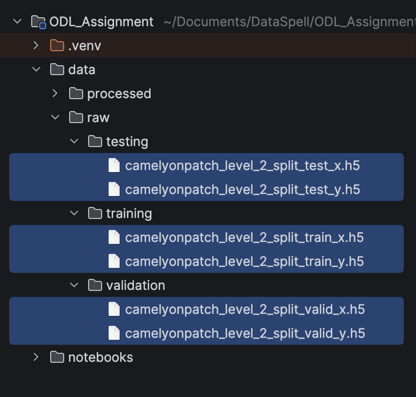
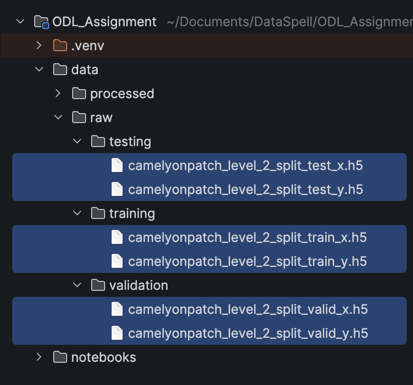

### 1.1 Check the size and number of rows for each dataset

In [8]:
# The names of each dataset split
SPLITS = ("train", "valid", "test")

# The mapping of each split to their number of samples
EXPECTED_N = {"train": N_TRAIN_FULL, "valid": N_VALID_FULL, "test": N_TEST_FULL}

# Retrieve the details of each dataset
rows = []
for name, path in H5_FILES.items():

    # Split the name into "train", "x"
    split, key = name.split("_")

    # Extract the information from the HDF5 file
    with h5py.File(path, "r") as file:
        rows.append({
            "file": path.name,
            "size_mb": round(path.stat().st_size / 1e6, 2),
            "rows": file[key].shape[0],
            "shape": file[key].shape,
            "expected": EXPECTED_N[split],
        })

# Convert the extracted details into table and display
files = pd.DataFrame(rows)
display(files)

,file,size_mb,rows,shape,expected
0,camelyonpatch_level_2_split_train_x.h5,7248.30,262144,"(262144, 96, 96, 3)",262144
1,camelyonpatch_level_2_split_train_y.h5,0.26,262144,"(262144, 1, 1, 1)",262144
2,camelyonpatch_level_2_split_valid_x.h5,906.04,32768,"(32768, 96, 96, 3)",32768
3,camelyonpatch_level_2_split_valid_y.h5,0.03,32768,"(32768, 1, 1, 1)",32768
4,camelyonpatch_level_2_split_test_x.h5,906.04,32768,"(32768, 96, 96, 3)",32768
5,camelyonpatch_level_2_split_test_y.h5,0.03,32768,"(32768, 1, 1, 1)",32768


### 1.2 Check the contents of the dataset

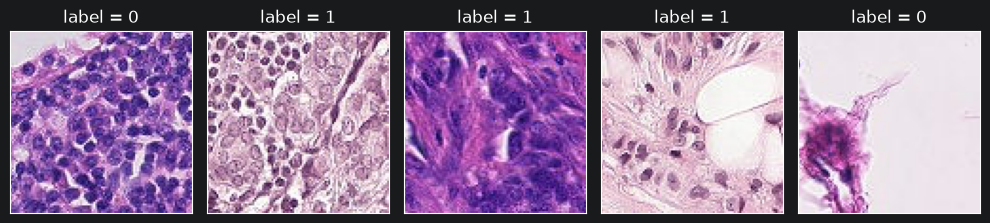

In [9]:
# Extract the first five images from the training dataset
with h5py.File(H5_FILES["train_x"], "r") as file:
    images = file["x"][:5]

# Extract the first five labels from the training dataset
with h5py.File(H5_FILES["train_y"], "r") as file:
    labels = file["y"][:5].reshape(-1)

# Display the first five patches with their labels
fig, axes = plt.subplots(1, 5, figsize=(10, 2.4))
for ax, image, label in zip(axes, images, labels):
    ax.imshow(image)
    ax.set_title(f"label = {label}")
    ax.set(xticks=[], yticks=[])
    ax.grid(False)
plt.tight_layout()
plt.show()

## Step 2: Dataset Structure

### 2.1 Check for Class Balance

In [10]:
# Read the labels of every split
labels = {}
for split in SPLITS:
    with h5py.File(H5_FILES[f"{split}_y"], "r") as file:
        labels[split] = file["y"][:].reshape(-1).astype(np.uint8)

# Count positive and negative patches per split
balance = pd.DataFrame([
    {
        "split": split,
        "n_images": len(y),
        "n_negative": int((y == 0).sum()),
        "n_positive": int((y == 1).sum()),
        "positive_rate": round(float(y.mean()), 4),
    }
    for split, y in labels.items()
])

# Display the table
display(balance)

,split,n_images,n_negative,n_positive,positive_rate
0,train,262144,131072,131072,0.5000
1,valid,32768,16399,16369,0.4995
2,test,32768,16391,16377,0.4998


### 2.2 Missing and Invalid Values

In [14]:
# Check if there is any blank image
for split in SPLITS:

    # Open the file
    blank = 0
    with h5py.File(H5_FILES[f"{split}_x"], "r") as file:

        # Point to the images and calculate the number of patches
        dset = file["x"]
        n = dset.shape[0]

        # Process images in batch of 2048
        for i in range(0, n, 2048):
            block = dset[i:i + 2048]

            # Check if there is images with maximum pixel value of 0
            blank += int((block.reshape(len(block), -1).max(axis=1) == 0).sum())

    # Once done, print the statistics
    print(f"{split:6} {n:>8,} patches | blank: {blank}")

# Check the value of the labels for each split
print()
for split in SPLITS:
    y = labels[split]
    print(split, "| unique labels:", np.unique(y))

train   262,144 patches | blank: 2
valid    32,768 patches | blank: 0
test     32,768 patches | blank: 0

train | unique labels: [0 1]
valid | unique labels: [0 1]
test | unique labels: [0 1]


## Step 3: Exploratory Data Analysis (EDA) on Images

 ### 3.1 Inspect Difference between Normal and Metastatic Patches

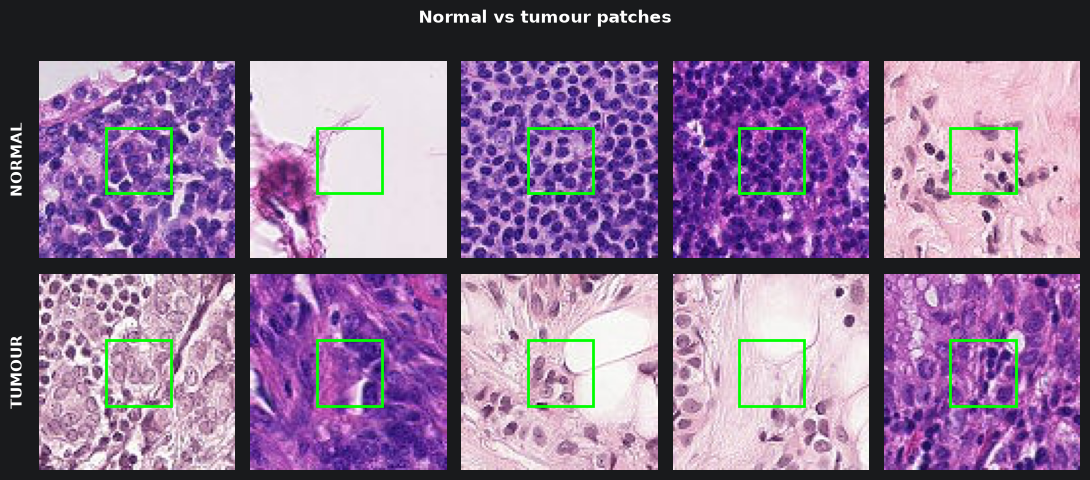

In [13]:
# C0 represents the start of the center region
C0 = (IMG_SIZE - CENTRE_REGION) // 2

# C1 represents the end of the center region
C1 = (IMG_SIZE + CENTRE_REGION) // 2

# Extract the IDs of five positive and negative samples from labels
y_train = labels["train"]
normal_idx = np.flatnonzero(y_train == 0)[:5]
tumour_idx = np.flatnonzero(y_train == 1)[:5]

# Extract the pictures based on the label IDs
with h5py.File(H5_FILES["train_x"], "r") as file:
    normal_x = file["x"][normal_idx]
    tumour_x = file["x"][tumour_idx]

# Loop through each picture
fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for row, (patches, name) in enumerate([(normal_x, "NORMAL"), (tumour_x, "TUMOUR")]):

    # Draw each picture
    for col, patch in enumerate(patches):
        ax = axes[row, col]
        ax.imshow(patch)
        ax.add_patch(plt.Rectangle((C0, C0), CENTRE_REGION, CENTRE_REGION, fill=False, color="lime", lw=2))
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        for spine in ax.spines.values():
            spine.set_visible(False)

    # Append row label at left
    axes[row, 0].set_ylabel(name, fontweight="bold", fontsize=11, labelpad=10)

# Add title and display the pictures
fig.suptitle("Normal vs tumour patches", fontweight="bold")
plt.tight_layout()
plt.show()

### 3.2 Tissue Content by Measuring Saturation

In [17]:
# Lists to store details
sat_max  = []       # This stores the saturation of each image
split_of = []       # This stores the split that the image originates from
row_of   = []       # This stores the position of the image in the split

# Loop through each split
for split in SPLITS:

    # Open the file
    with h5py.File(H5_FILES[f"{split}_x"], "r") as file:

        # Get the image column
        dset = file["x"]
        n = dset.shape[0]

        # Process images in batches of 2048
        for i in range(0, n, 2048):

            # Convert the pixel value to the range of [0, 1]
            x = dset[i:i + 2048].astype(np.float32) / 255.0

            # Saturation per pixel: (brightest channel - dimmest channel) / brightest channel
            mx, mn = x.max(axis=3), x.min(axis=3)
            sat = (mx - mn) / np.maximum(mx, 1e-6)

            # Add the maximum saturation to the list
            sat_max.append(sat.reshape(len(x), -1).max(axis=1))

    # Record the details of the images
    split_of += [split] * n
    row_of.append(np.arange(n))

# Compile the details into a table
qual = pd.DataFrame({
    "split": split_of,
    "row": np.concatenate(row_of),
    "max_saturation": np.concatenate(sat_max),
})

# Official PCam uses a threshold of 0.07, so those below the threshold are considered low info
SATURATION_THRESHOLD = 0.07
qual["low_tissue"] = qual["max_saturation"] < SATURATION_THRESHOLD

# List down the IDs to be excluded from sampling later
exclude_idx = {s: qual.loc[(qual.split == s) & qual.low_tissue, "row"].to_numpy()
               for s in SPLITS}

# Show the statistics of the low info tissue in each split
summary = qual.groupby("split", sort=False).agg(
    n_patches=("split", "size"),
    low_tissue=("low_tissue", "sum"),
)
display(summary)

,n_patches,low_tissue
split,,
train,262144,505
valid,32768,55
test,32768,62


#### 3.2.1 Examples of Tissue with Low Saturation

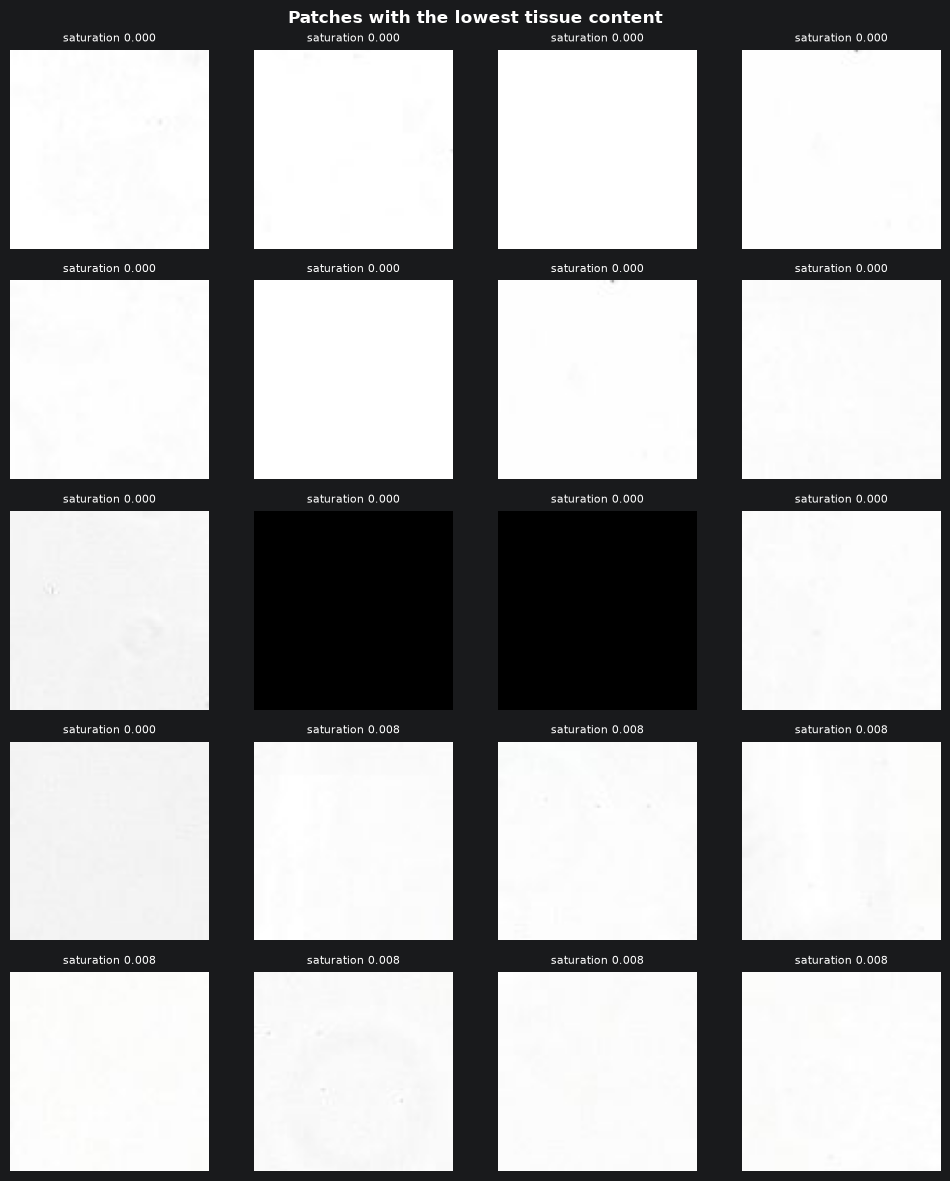

In [18]:
# Show some samples that is below maximum threshold
lowest = qual.nsmallest(20, "max_saturation")
fig, axes = plt.subplots(5, 4, figsize=(10, 12))
for ax, (_, patch) in zip(axes.ravel(), lowest.iterrows()):
    with h5py.File(H5_FILES[f"{patch['split']}_x"], "r") as file:
        ax.imshow(file["x"][int(patch["row"])])
    ax.set_title(f"saturation {patch['max_saturation']:.3f}", fontsize=8)
    ax.axis("off")
fig.suptitle("Patches with the lowest tissue content", fontweight="bold")
plt.tight_layout()
plt.show()

### 3.3 Duplication Check

In [21]:
# A dictionary to store hash values
hashes = {}

# Loop through each split
for split in SPLITS:
    h = []

    # Open each file
    with h5py.File(H5_FILES[f"{split}_x"], "r") as file:

        # Extract the image column
        dset = file["x"]
        n = dset.shape[0]

        # Convert each image to hash values and add to list
        for i in range(0, n, 2048):
            for image in dset[i:i + 2048]:
                h.append(hashlib.sha256(image.tobytes()).hexdigest())

    # Add the hash values to the dict
    hashes[split] = pd.Series(h)

# Calculate and display duplicates in table format
duplicates = pd.DataFrame([
    {"split": split,
     "n_patches": len(h),
     "unique": h.nunique(),
     "duplicates": int(h.duplicated().sum())}
    for split, h in hashes.items()
])
display(duplicates)

# Check whether any image appears in more than one split
train, valid, test = (set(hashes[s]) for s in SPLITS)
print("train & test :", len(train & test))
print("train & valid:", len(train & valid))
print("valid & test :", len(valid & test))

# Retrieve the hash value of the images that are duplicated and leaked
train_hashes = hashes["train"]
repeat_rows = np.flatnonzero(train_hashes.duplicated())
leaked_rows = np.flatnonzero(train_hashes.isin(test))

# Add the rows to be excluded into the exclude_idx list
drop_rows = np.union1d(repeat_rows, leaked_rows)
exclude_idx["train"] = np.union1d(exclude_idx["train"], drop_rows)

,split,n_patches,unique,duplicates
0,train,262144,220025,42119
1,valid,32768,28108,4660
2,test,32768,29383,3385


train & test : 33
train & valid: 0
valid & test : 0


## Step 4: Data Preparation

### 4.1 Stratify Dataset

In [22]:
# Use 70k to maintain computational feasibility
TRAIN_SUBSET = 70_000

# Set a seed for reproducibility
rng = np.random.default_rng(SEED)

# Extract the labels for training
y_train = labels["train"]

# Mark the IDs that are not usable as false
usable = np.ones(len(y_train), dtype=bool)
usable[exclude_idx["train"]] = False

# Perform sampling by taking half from each positive and negative class
sub_idx = np.sort(np.concatenate([
    rng.choice(np.flatnonzero((y_train == label) & usable),
               TRAIN_SUBSET // 2, replace=False)
    for label in (0, 1)
]))
sub_y = y_train[sub_idx]

# Loop through all splits
for split in SPLITS:

    # Rename the stratified dataset and declare their directory
    tag = f"sub{TRAIN_SUBSET}" if split == "train" else "full"
    x_path = PROCESSED_DIRECTORY / f"{split}_{tag}_x.npy"
    y_path = PROCESSED_DIRECTORY / f"{split}_{tag}_y.npy"

    # Create the placeholder image array for the training dataset
    rows = sub_idx if split == "train" else np.arange(EXPECTED_N[split])
    images = np.empty((len(rows), IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)

    # Load the actual image data into the array
    with h5py.File(H5_FILES[f"{split}_x"], "r") as file:
        dset = file["x"]
        for i in range(0, len(rows), 2048):
            block = rows[i:i + 2048]
            images[i:i + len(block)] = dset[block]

    # Save the dataset
    np.save(x_path, images)
    np.save(y_path, labels[split][rows])
    print(f"{split:6} saved {len(rows):,} patches -> {x_path.name}")

# Compile and display the details of the three splits
prepared = {"train (subset)": sub_y,
            "valid (full)": labels["valid"],
            "test (full)": labels["test"]}
subset_summary = pd.DataFrame([
    {"split": name,
     "n_patches": len(y),
     "negative": int((y == 0).sum()),
     "positive": int((y == 1).sum()),
     "positive_rate": round(float(y.mean()), 4)}
    for name, y in prepared.items()
])
display(subset_summary)

train  saved 70,000 patches -> train_sub70000_x.npy
valid  saved 32,768 patches -> valid_full_x.npy
test   saved 32,768 patches -> test_full_x.npy


,split,n_patches,negative,positive,positive_rate
0,train (subset),70000,35000,35000,0.5000
1,valid (full),32768,16399,16369,0.4995
2,test (full),32768,16391,16377,0.4998


### 4.2 Data Normalisation

In [23]:
# Load the stratified training set
xtr = np.load(PROCESSED_DIRECTORY / f"train_sub{TRAIN_SUBSET}_x.npy", mmap_mode="r")

# Arrays to store sum (total) and sum of squares (total_sq) to calculate std dev
total = np.zeros(3, dtype=np.float64)
total_sq = np.zeros(3, dtype=np.float64)
count = 0

# Loop through images in batches of 2048
for i in range(0, len(xtr), 2048):

    # Rescale the pixel values to the range of [0, 1]
    batch = np.asarray(xtr[i:i + 2048], dtype=np.float64) / 255.0

    # Record the values into sum and sum of squares
    total += batch.sum(axis=(0, 1, 2))
    total_sq += np.square(batch).sum(axis=(0, 1, 2))

    # Add the number of pixels to count
    count += batch.shape[0] * batch.shape[1] * batch.shape[2]

# Calculate the mean and std dev for each color channel (red, green and blue)
CH_MEAN = total / count
CH_STD = np.sqrt(np.maximum(total_sq / count - CH_MEAN ** 2, 0.0))

# Print the calculations
print("Normalization statistics:")
for channel, name in enumerate(["Red", "Green", "Blue"]):
    print(f"  {name:<6} mean = {CH_MEAN[channel]:.4f},   std = {CH_STD[channel]:.4f}")

# Save the values to a file to be used during training
np.savez(PROCESSED_DIRECTORY / "channel_stats.npz", mean=CH_MEAN.astype(np.float32), std=CH_STD.astype(np.float32))

Normalization statistics:
  Red    mean = 0.7008,   std = 0.2346
  Green  mean = 0.5393,   std = 0.2763
  Blue   mean = 0.6949,   std = 0.2117


### 4.3 Data augmentation

#### 4.3.1 Color Deconvolution

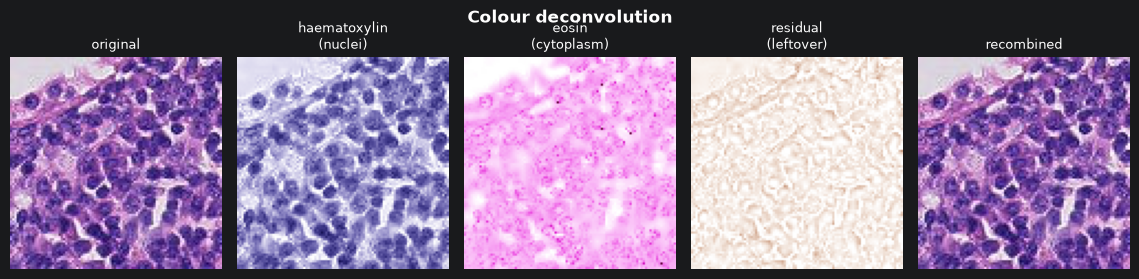

In [27]:
# Color matrix from Ruifrok & Johnston (2001)
# Used to rebuild image from stain
STAIN_COLOURS = torch.tensor([
    [0.65, 0.70, 0.29],
    [0.07, 0.99, 0.11],
    [0.27, 0.57, 0.78],
], dtype=torch.float32)

# Inverse of the color matrix to separate pictures into different layers
DECONVOLUTION = torch.linalg.inv(STAIN_COLOURS)

# The function to convert patches into different layers
def rgb_to_hed(x):
    density = -torch.log(x.clamp_min(1e-6))
    return torch.einsum("nchw,cd->ndhw", density, DECONVOLUTION.to(x.device))

# The function to convert layers back into patches
def hed_to_rgb(stains):
    density = torch.einsum("nchw,cd->ndhw", stains, STAIN_COLOURS.to(stains.device))
    return torch.exp(-density).clamp(0, 1)

# Take one patch as sample for demonstration
sample = torch.from_numpy(np.ascontiguousarray(xtr[:1])).permute(0, 3, 1, 2).float() / 255
stains = rgb_to_hed(sample)

# A helper function to display the deconvoluted images
def isolate(index):
    only = torch.zeros_like(stains)         # Create an array full of zero
    only[:, index] = stains[:, index]       # Copy the value for a stain to the array
    return hed_to_rgb(only)                 # Convert back into RGB to display

# A dict to store the deconvolution details
columns = {
    "original": sample,
    "haematoxylin\n(nuclei)": isolate(0),
    "eosin\n(cytoplasm)": isolate(1),
    "residual\n(leftover)": isolate(2),
    "recombined": hed_to_rgb(stains),
}

# Display the images involved in the deconvolution operation
fig, axes = plt.subplots(1, len(columns), figsize=(2.3 * len(columns), 2.8))
for ax, (name, images) in zip(axes, columns.items()):
    ax.imshow(images[0].permute(1, 2, 0).numpy())
    ax.set_title(name, fontsize=9)
    ax.axis("off")
fig.suptitle("Colour deconvolution", fontweight="bold")
plt.tight_layout()
plt.show()

#### 4.3.2 D4 Dihedral Transformation

In [29]:
def d4_dihedral(x):
    for transform in (lambda t: t.transpose(-2, -1),        # Swap rows and columns
                      lambda t: t.flip(-2),                 # Flip upside down
                      lambda t: t.flip(-1)):                # Flip left to right
        coin = torch.rand(len(x), 1, 1, 1, device=x.device) < 0.5
        x = torch.where(coin, transform(x), x)
    return x

#### 4.3.3. H&E Stain Jitter

In [30]:
def he_stain_jitter(x, strength=0.05):

    # Do nothing if strength is specified as 0
    if strength <= 0:
        return x

    # Deconvolute the patch
    stains = rgb_to_hed(x)

    # Perform scaling and shifting
    shape = (len(x), 2, 1, 1)                                               # Define the slot to store scale and shift values
    scale = 1 + (torch.rand(shape, device=x.device) * 2 - 1) * strength     # [ 0, 2] if strength is 1
    shift = (torch.rand(shape, device=x.device) * 2 - 1) * strength         # [-1, 1] if strength is 1

    # Update and return the values for modification
    jittered = torch.cat([stains[:, :2] * scale + shift, stains[:, 2:]], dim=1)
    return hed_to_rgb(jittered)

#### 4.3.4 Photometric Jitter

In [31]:
def photometric_jitter(x, strength=0.15):

    # Perform nothing if strength = 0
    if strength <= 0:
        return x

    # Generate individual scale factor in range of [1 - strength, 1 + strength]
    factors = 1 + (torch.rand(3, len(x), 1, 1, 1, device=x.device) * 2 - 1) * strength
    brightness, contrast, saturation = factors

    # Update brightness
    x = x * brightness

    # Update contrast
    mean = x.mean(dim=(1, 2, 3), keepdim=True)
    x = (x - mean) * contrast + mean

    # Update saturation
    gray = rgb_to_grayscale(x)
    x = (x - gray) * saturation + gray

    # Return the updated value
    return x

#### 4.3.5 Combining all into augment

In [32]:
def augment(patches, d4=True, hed_strength=0.05, photometric=0.15):

    # Perform normalization on the pixel values
    x = patches.float() / 255.0 if patches.dtype == torch.uint8 else patches

    # Apply the different augmentation techniques
    if d4:
        x = d4_dihedral(x)
    x = he_stain_jitter(x, strength=hed_strength)
    x = photometric_jitter(x, strength=photometric)

    # Return the augmented value
    return x.clamp(0, 1)

#### 4.3.6 Augmentation Demonstration

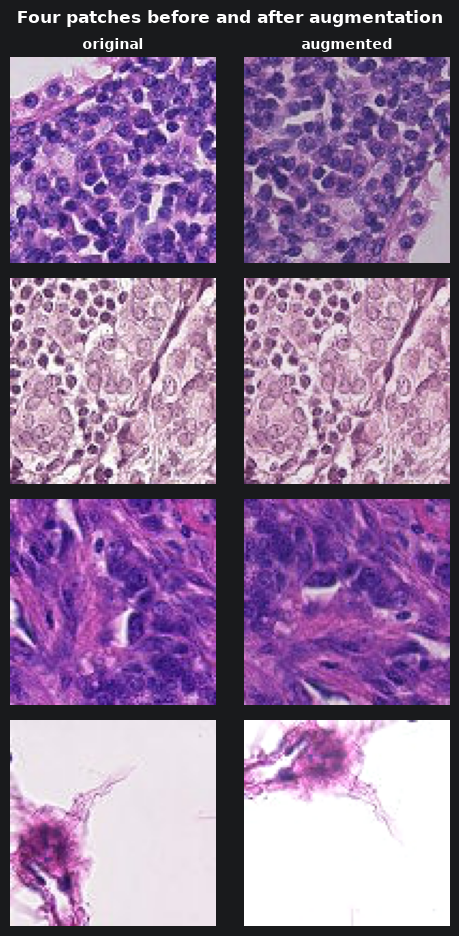

In [35]:
# Select 4 patches
patches = torch.from_numpy(np.ascontiguousarray(xtr[:4])).permute(0, 3, 1, 2)

# Apply augmentation
torch.manual_seed(0)
columns = {
    "original": augment(patches, d4=False, hed_strength=0, photometric=0),
    "augmented": augment(patches),
}

# Show output of the 4 patches
fig, axes = plt.subplots(4, 2, figsize=(5, 9.5))
for col, (name, images) in enumerate(columns.items()):
    images = images.permute(0, 2, 3, 1).numpy()
    for row in range(4):
        axes[row, col].imshow(images[row])
        axes[row, col].set_xticks([]); axes[row, col].set_yticks([])
        for spine in axes[row, col].spines.values():
            spine.set_visible(False)
    axes[0, col].set_title(name, fontsize=10, fontweight="bold")
fig.suptitle("Four patches before and after augmentation", fontweight="bold")
plt.tight_layout()
plt.show()

# Step 5: Final Verification

In [36]:
# Retrieve the saved .npy files
prepared = {}
for split in SPLITS:
    tag = f"sub{TRAIN_SUBSET}" if split == "train" else "full"
    prepared[split] = (
        np.load(PROCESSED_DIRECTORY / f"{split}_{tag}_x.npy", mmap_mode="r"),
        np.load(PROCESSED_DIRECTORY / f"{split}_{tag}_y.npy"),
    )

# Perform hashing to evaluate for duplicates and leakage
prepared_hashes = {}
for split, (images, _) in prepared.items():
    h = []
    for i in range(0, len(images), 2048):
        for image in images[i:i + 2048]:
            h.append(hashlib.sha256(image.tobytes()).hexdigest())
    prepared_hashes[split] = pd.Series(h)

# Calculate the maximum saturation of every patch
prepared_saturation = {}
for split, (images, _) in prepared.items():
    values = []
    for i in range(0, len(images), 2048):
        x = images[i:i + 2048].astype(np.float32) / 255.0
        mx, mn = x.max(axis=3), x.min(axis=3)
        sat = (mx - mn) / np.maximum(mx, 1e-6)
        values.append(sat.reshape(len(x), -1).max(axis=1))
    prepared_saturation[split] = np.concatenate(values)

# Perform checking on each split
report = []
for split, (images, labels_split) in prepared.items():
    h = prepared_hashes[split]
    other = set().union(*(set(prepared_hashes[s]) for s in SPLITS if s != split))
    report.append({
        "split": split,
        "patches": len(images),
        "shape": str(images.shape[1:]),
        "dtype": str(images.dtype),
        "blank_patches": int((images.reshape(len(images), -1).max(axis=1) == 0).sum()),
        "invalid_labels": int((~np.isin(labels_split, [0, 1])).sum()),
        "duplicates": int(h.duplicated().sum()),
        "shared_with_other_splits": int(h.isin(other).sum()),
        "below_saturation_0.07": int((prepared_saturation[split] < SATURATION_THRESHOLD).sum()),
        "negative": int((labels_split == 0).sum()),
        "positive": int((labels_split == 1).sum()),
        "positive_rate": round(float(labels_split.mean()), 4),
    })

# Display the results
checks = pd.DataFrame(report).set_index("split")
display(checks.T)

# Also display the normalization statistics
stats = np.load(PROCESSED_DIRECTORY / "channel_stats.npz")
print(f"Channel means : {stats['mean'].round(4)}")
print(f"Channel stds  : {stats['std'].round(4)}")

split,train,valid,test
patches,70000,32768,32768
shape,"(96, 96, 3)","(96, 96, 3)","(96, 96, 3)"
dtype,uint8,uint8,uint8
blank_patches,0,0,0
invalid_labels,0,0,0
duplicates,0,4660,3385
shared_with_other_splits,0,0,0
below_saturation_0.07,0,55,62
negative,35000,16399,16391
positive,35000,16369,16377


Channel means : [0.7008 0.5393 0.6949]
Channel stds  : [0.2346 0.2763 0.2117]
